# DynamicAuc Environment Tutorial

This notebook focuses on interacting with the Gym-compatible `AuctionEnv`. It specifically demonstrates the **delayed reward** mechanism, where past actions result in conversions that are reported to the agent in subsequent observations.

## 1. Setup and Imports
We will load our dynamicauc components and visualization tools.

In [1]:
import dynamicauc as dac
from dynamicauc.policies import FiPlaPolicy
import gymnasium as gym
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style='whitegrid')

## 2. Environment Interaction Loop
We will use the `mixed` kernel, which generates both immediate and delayed conversions. We run a single episode and record everything the agent observes into a DataFrame.

In [12]:
scenario = dac.make('mixed-second-price-exponential', horizon=100.0, kernel_base_kernel_delay_rate=0.5)
env = gym.make('DynamicAuction-v0', scenario=scenario)
policy = FiPlaPolicy()

obs, info = env.reset(seed=123)
done = False
history = []
cum_reward = 0.0

while not done:
    # Agent decides on a bid
    bid = policy.bid(obs)
    pre_step_obs = obs
    
    # Agent takes action
    obs, net_reward, done, truncated, step_info = env.step(bid)
    
    cum_reward += net_reward
    
    # Record state for visualization
    history.append({
        'step': pre_step_obs['step'],
        'time': pre_step_obs['t'].item(),
        'context': pre_step_obs['ctx'].item(),
        'expected_reward': pre_step_obs['expected_reward'].item(),
        'delayed_reward_observed': pre_step_obs['cumulative_reward_since_last_step'].item(),
        'conversion_times_since_last': [t.item() for t in pre_step_obs['conversion_times_since_last_step']],
        'bid': bid,
        'won': step_info['auction']['won'],
        'immediate_reward': net_reward,
        'cumulative_reward': cum_reward
    })

df = pd.DataFrame(history)
df.head(40)

,step,time,context,expected_reward,delayed_reward_observed,conversion_times_since_last,bid,won,immediate_reward,cumulative_reward
0,0,1.447448,0.0,0.700000,0.0,[],0.700000,True,-0.244663,-0.244663
1,1,1.489492,1.0,0.652419,0.0,[],0.652419,True,-0.209870,-0.454532
2,2,3.255192,2.0,0.609365,1.0,[2.198204278945923],0.609365,True,-0.259732,-0.714265
3,3,7.148681,3.0,0.570409,1.0,[5.653106689453125],0.570409,False,0.000000,-0.714265
4,4,16.590399,3.0,0.570409,0.0,[],0.570409,True,-0.164656,-0.878921
5,5,17.363163,4.0,0.535160,0.0,[],0.535160,True,0.901235,0.022314
6,6,18.433798,5.0,0.503265,2.0,"[17.502300262451172, 18.3992919921875]",0.503265,False,0.000000,0.022314
7,7,21.376297,5.0,0.503265,0.0,[],0.503265,False,0.000000,0.022314
8,8,21.814287,5.0,0.503265,0.0,[],0.503265,True,-0.110999,-0.088684
9,9,23.155563,6.0,0.474406,0.0,[],0.474406,False,0.000000,-0.088684


## 3. Visualization: Auction Timeline
Let's map out when the agent bid, whether it won or lost, and when it received notifications of delayed conversions.

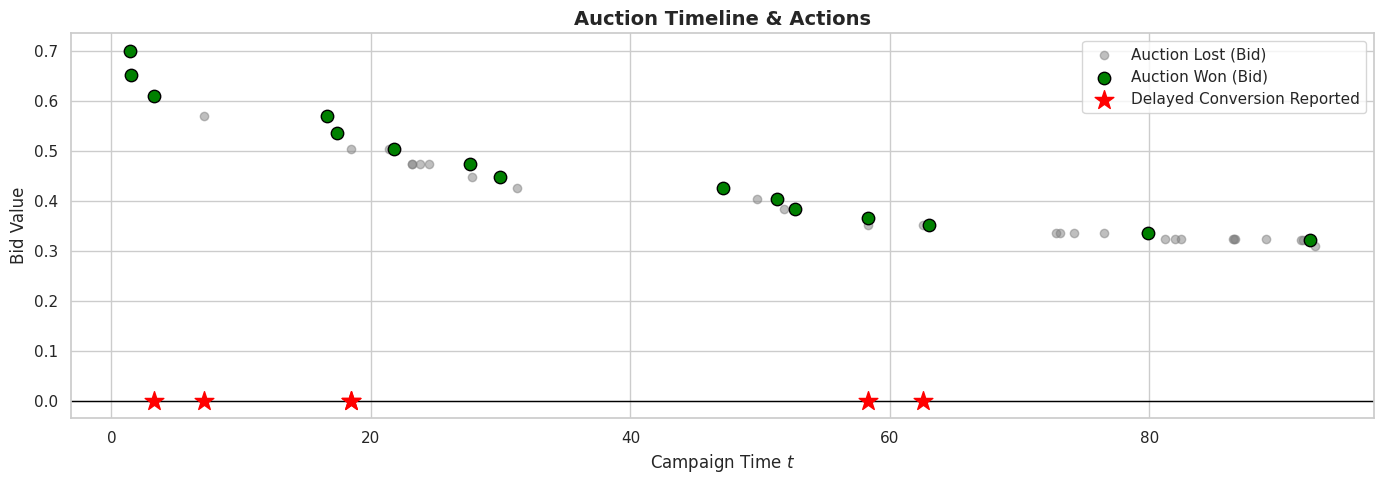

In [9]:
def plot_auction_timeline(df):
    plt.figure(figsize=(14, 5))
    
    lost = df[~df['won']]
    won = df[df['won']]
    
    plt.scatter(lost['time'], lost['bid'], color='gray', alpha=0.5, label='Auction Lost (Bid)')
    plt.scatter(won['time'], won['bid'], color='green', s=80, label='Auction Won (Bid)', edgecolor='black')
    
    # Plot when delayed conversions were reported to the agent
    reported_times = []
    for _, row in df.iterrows():
        if row['delayed_reward_observed'] > 0:
            # Add one marker per conversion reported
            reported_times.extend([row['time']] * int(row['delayed_reward_observed']))
            
    if reported_times:
        plt.scatter(reported_times, [0] * len(reported_times), color='red', marker='*', s=200, label='Delayed Conversion Reported', zorder=5)
        
    plt.title('Auction Timeline & Actions', fontsize=14, weight='bold')
    plt.xlabel('Campaign Time $t$')
    plt.ylabel('Bid Value')
    plt.axhline(0, color='black', linewidth=1)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

plot_auction_timeline(df)

## 4. Visualization: Step-by-Step Reward Dynamics
Because of the delayed environment, the agent receives two types of feedback: immediate feedback for the current action, and delayed feedback from past actions that matured.

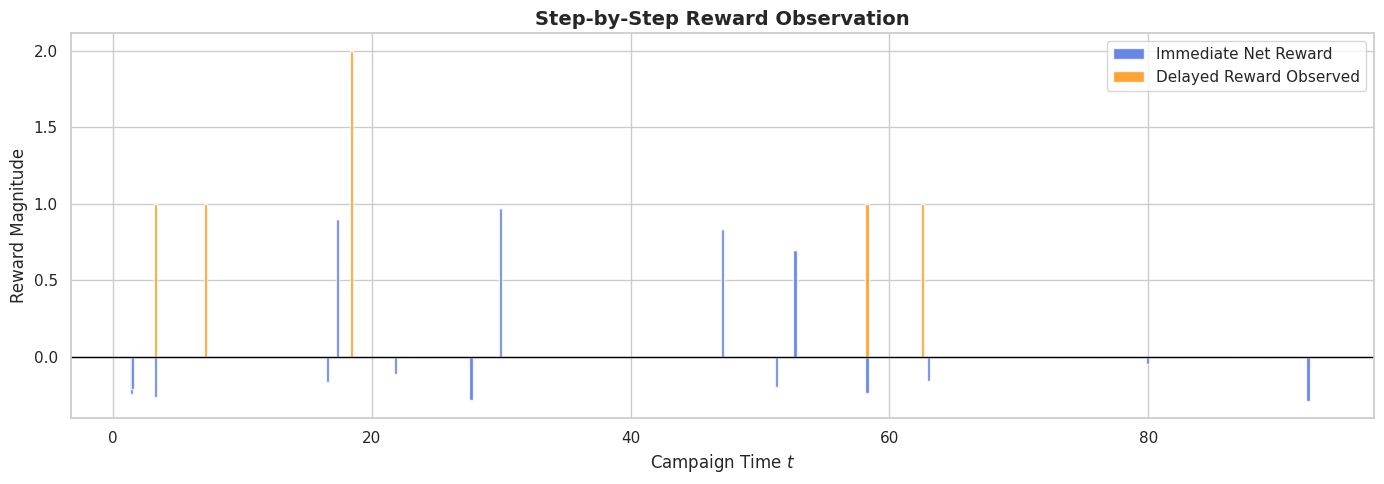

In [10]:
def plot_reward_dynamics(df):
    plt.figure(figsize=(14, 5))
    
    plt.bar(df['time'], df['immediate_reward'], width=0.25, label='Immediate Net Reward', color='royalblue', alpha=0.8)
    
    # Stack delayed rewards on top of immediate positive rewards for visibility
    plt.bar(df['time'], df['delayed_reward_observed'], width=0.25, bottom=np.maximum(0, df['immediate_reward']), label='Delayed Reward Observed', color='darkorange', alpha=0.8)
    
    plt.title('Step-by-Step Reward Observation', fontsize=14, weight='bold')
    plt.xlabel('Campaign Time $t$')
    plt.ylabel('Reward Magnitude')
    plt.axhline(0, color='black', linewidth=1)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_reward_dynamics(df)

## 5. Visualization: Cumulative Metrics and Degradation
Finally, we can look at the overarching trend of the episode. As the agent wins more auctions, the cumulative reward goes up, but the `expected_reward` (value of future displays) goes down due to saturation.

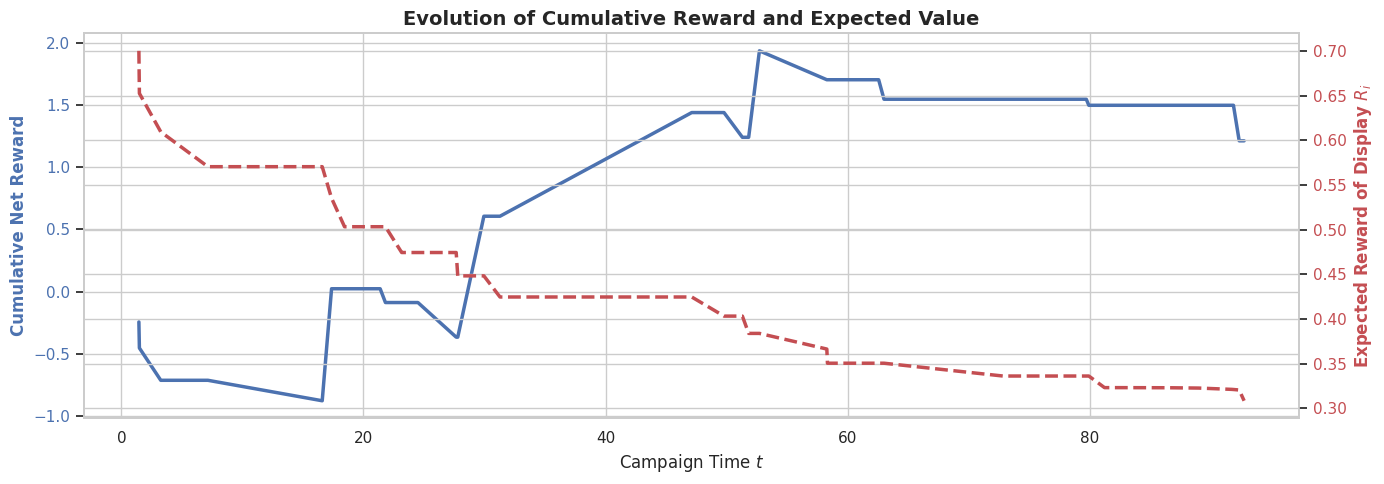

In [11]:
def plot_cumulative_metrics(df):
    fig, ax1 = plt.subplots(figsize=(14, 5))
    
    ax1.plot(df['time'], df['cumulative_reward'], 'b-', linewidth=2.5, label='Cumulative Net Reward')
    ax1.set_xlabel('Campaign Time $t$')
    ax1.set_ylabel('Cumulative Net Reward', color='b', weight='bold')
    ax1.tick_params(axis='y', labelcolor='b')
    
    ax2 = ax1.twinx()
    ax2.plot(df['time'], df['expected_reward'], 'r--', linewidth=2.5, label='Expected Reward (State)')
    ax2.set_ylabel('Expected Reward of Display $R_i$', color='r', weight='bold')
    ax2.tick_params(axis='y', labelcolor='r')
    
    plt.title('Evolution of Cumulative Reward and Expected Value', fontsize=14, weight='bold')
    fig.tight_layout()
    plt.show()

plot_cumulative_metrics(df)